 <div align="center">

# 🛡️ **ToxiGuard – Toxic Comment Detection Using NLP and Bidirectional LSTM**

### Natural Language Processing and Deep Learning for Toxic Comment Classification

<img src="https://i.postimg.cc/TYf0bLrm/Beauty-Filters.jpg" width="800">

</div>

---

## **📌 Project Overview**

ToxiGuard is a Natural Language Processing (NLP) and Deep Learning project designed to identify and classify toxic comments in online text.

The project uses text preprocessing, exploratory data analysis, and a Bidirectional Long Short-Term Memory (BiLSTM) neural network to detect different categories of toxic language.

It focuses on identifying harmful comments across six categories: toxic, severe toxic, obscene, threat, insult, and identity hate.

The project combines **Exploratory Data Analysis (EDA), Natural Language Processing, and Deep Learning techniques** to understand text patterns and develop an automated toxic comment classification model.

---

## **🎯 Objectives**

* Understand the structure and characteristics of the toxic comment dataset.
* Perform data quality checks and identify missing values and duplicate records.
* Analyze the distribution of toxic and non-toxic comments.
* Explore the frequency of different toxicity categories.
* Perform text preprocessing and cleaning.
* Analyze comment length and common word patterns.
* Convert text into numerical representations suitable for machine learning.
* Build a baseline Machine Learning model for toxic comment classification.
* Develop a Bidirectional LSTM model for text classification.
* Evaluate model performance using appropriate classification metrics.
* Compare the performance of Machine Learning and Deep Learning models.
* Predict multiple toxicity categories for a given comment.

---

## **📊 Dataset**

The project uses the **Jigsaw Toxic Comment Classification Challenge** dataset from Kaggle.

The primary training dataset, `train.csv`, contains **159,571 rows and 8 columns** in the original dataset.

It includes the comment text and six binary target labels:

* `toxic`
* `severe_toxic`
* `obscene`
* `threat`
* `insult`
* `identity_hate`

Each comment can belong to multiple toxicity categories, making this a **multi-label text classification** problem.

---

## **🛠️ Tools & Technologies**

* Python
* Pandas
* NumPy
* Matplotlib
* Seaborn
* Scikit-learn
* Natural Language Processing (NLP)
* TensorFlow / Keras
* Google Colab

---

## **🤖 Machine Learning & Deep Learning Techniques**

### **1. TF-IDF Vectorization**

Used to convert textual comments into numerical features based on word importance.

### **2. Logistic Regression**

Used as a baseline Machine Learning model to classify toxic comments using TF-IDF features.

### **3. Bidirectional LSTM (BiLSTM)**

Used to learn contextual patterns in text by processing sequences in both forward and backward directions.

### **4. Model Evaluation**

Model performance will be evaluated using appropriate metrics such as Precision, Recall, F1-score, and ROC-AUC, where applicable.

---

## **📈 Expected Outcome**

The project aims to develop a text classification system capable of identifying multiple categories of toxic comments.

It demonstrates practical skills in data cleaning, exploratory data analysis, text preprocessing, feature extraction, Machine Learning, Deep Learning, model evaluation, and NLP-based classification.

The project also provides hands-on experience in building a BiLSTM model for real-world text classification applications.

---

## **🚀 Future Enhancements**

* Develop an interactive interface for entering comments and obtaining predictions.
* Integrate the trained model into a simple web application.
* Explore advanced NLP models such as BERT.
* Improve classification performance for underrepresented toxicity categories.

In [ ]:
import pandas as pd
import zipfile
import os

# Extract the training dataset
zip_path = "/train.csv.zip"
extract_path = "/content/"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
# Load the training dataset
df = pd.read_csv("/train.csv.zip")

# Display the first 5 rows
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [ ]:
# Check the dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 159571
Number of columns: 8


In [ ]:
# Display all column names
print("Dataset Columns:\n")
print(df.columns.tolist())

Dataset Columns:

['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


In [ ]:
# Check the data types of all columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   id             159571 non-null  object
 1   comment_text   159571 non-null  object
 2   toxic          159571 non-null  int64 
 3   severe_toxic   159571 non-null  int64 
 4   obscene        159571 non-null  int64 
 5   threat         159571 non-null  int64 
 6   insult         159571 non-null  int64 
 7   identity_hate  159571 non-null  int64 
dtypes: int64(6), object(2)
memory usage: 9.7+ MB


In [ ]:
# Check missing values in each column
print(df.isnull().sum())

id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64


In [ ]:
# Check the number of duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [ ]:
# Define the six toxicity labels
toxicity_labels = [
    'toxic',
    'severe_toxic',
    'obscene',
    'threat',
    'insult',
    'identity_hate'
]

# Count positive examples for each label
for label in toxicity_labels:
    print(f"{label}: {df[label].sum()}")

toxic: 15294
severe_toxic: 1595
obscene: 8449
threat: 478
insult: 7877
identity_hate: 1405


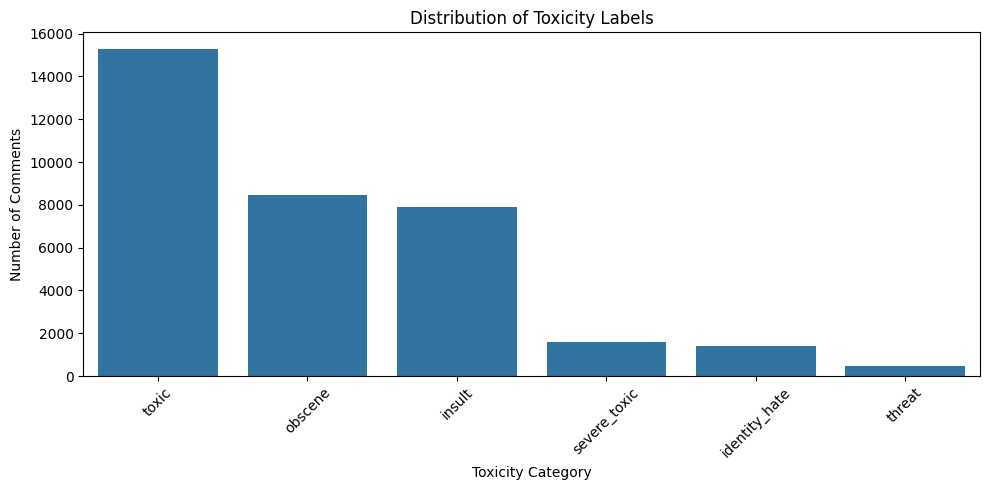

In [ ]:
#Visualize the toxicity label distribution
import matplotlib.pyplot as plt
import seaborn as sns

# Count positive examples for each toxicity label
label_counts = df[toxicity_labels].sum().sort_values(ascending=False)

# Create the bar chart
plt.figure(figsize=(10, 5))
sns.barplot(x=label_counts.index, y=label_counts.values)

plt.title("Distribution of Toxicity Labels")
plt.xlabel("Toxicity Category")
plt.ylabel("Number of Comments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#Analyze Comment Length
# Calculate the length of each comment
df['comment_length'] = df['comment_text'].apply(len)

# Display descriptive statistics
print("Comment Length Statistics:")
print(df['comment_length'].describe())

Comment Length Statistics:
count    159571.000000
mean        394.073221
std         590.720282
min           6.000000
25%          96.000000
50%         205.000000
75%         435.000000
max        5000.000000
Name: comment_length, dtype: float64


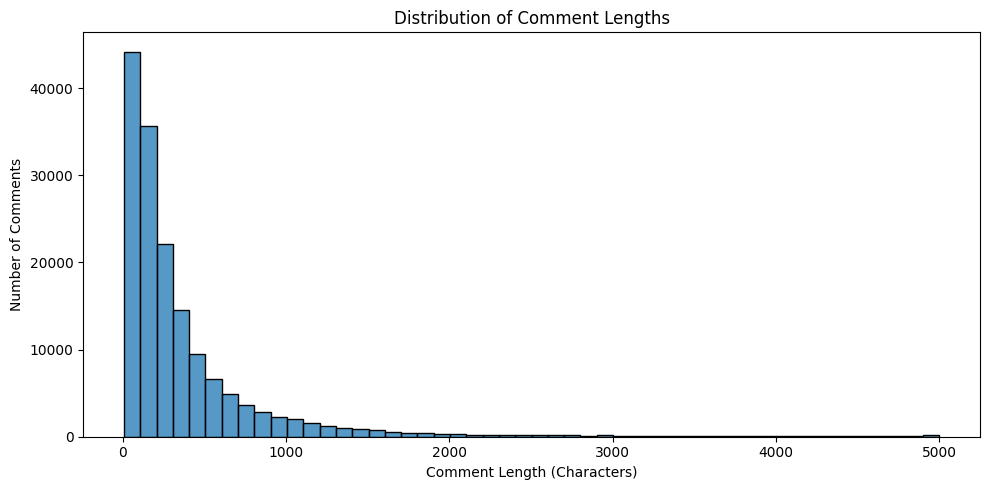

In [ ]:
# Visualize comment length distribution
plt.figure(figsize=(10, 5))

sns.histplot(df['comment_length'], bins=50, kde=False)

plt.title("Distribution of Comment Lengths")
plt.xlabel("Comment Length (Characters)")
plt.ylabel("Number of Comments")
plt.tight_layout()
plt.show()

In [ ]:
# Count toxic and non-toxic comments
toxic_count = df['toxic'].sum()
non_toxic_count = (df['toxic'] == 0).sum()

print("Toxic comments:", toxic_count)
print("Non-toxic comments:", non_toxic_count)

Toxic comments: 15294
Non-toxic comments: 144277


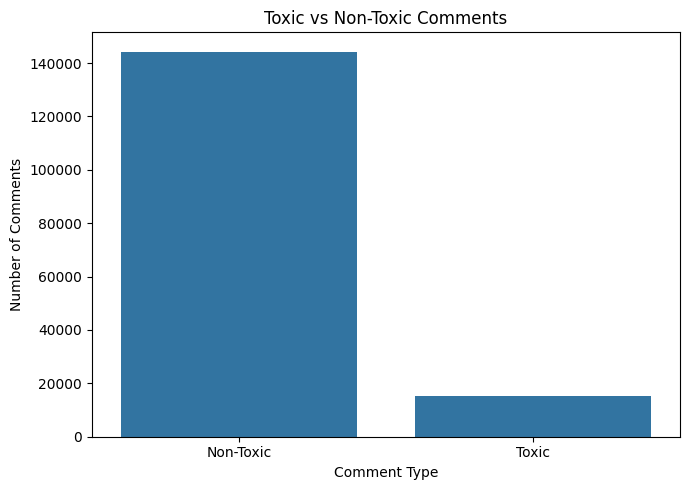

In [ ]:
# Prepare toxic and non-toxic comment counts
comment_types = ['Non-Toxic', 'Toxic']
comment_counts = [
    (df['toxic'] == 0).sum(),
    df['toxic'].sum()
]

# Create bar chart
plt.figure(figsize=(7, 5))
sns.barplot(x=comment_types, y=comment_counts)

plt.title("Toxic vs Non-Toxic Comments")
plt.xlabel("Comment Type")
plt.ylabel("Number of Comments")
plt.tight_layout()
plt.show()

In [ ]:
# Count how many toxicity labels apply to each comment
df['toxicity_count'] = df[toxicity_labels].sum(axis=1)

# Display the number of comments for each label count
print("Number of toxicity labels per comment:\n")
print(df['toxicity_count'].value_counts().sort_index())

Number of toxicity labels per comment:

toxicity_count
0    143346
1      6360
2      3480
3      4209
4      1760
5       385
6        31
Name: count, dtype: int64


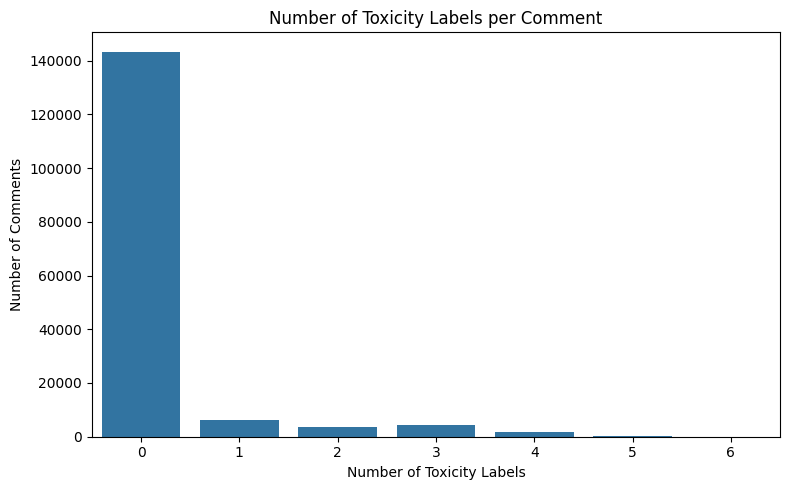

In [ ]:
# Visualize the number of toxicity labels per comment
label_count_distribution = df['toxicity_count'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(
    x=label_count_distribution.index,
    y=label_count_distribution.values
)

plt.title("Number of Toxicity Labels per Comment")
plt.xlabel("Number of Toxicity Labels")
plt.ylabel("Number of Comments")
plt.tight_layout()
plt.show()

In [ ]:
#Find the Most Common Words
from collections import Counter
import re

# Combine all comments into one text
all_text = " ".join(df['comment_text'].astype(str)).lower()

# Extract words
words = re.findall(r'\b[a-z]+\b', all_text)

# Count the most frequent words
common_words = Counter(words).most_common(20)

# Display the 20 most common words
for word, count in common_words:
    print(f"{word}: {count}")

the: 496796
to: 297408
i: 240405
of: 224547
and: 224092
you: 218308
a: 215943
is: 176405
that: 160867
it: 148644
in: 145477
for: 102723
this: 97655
not: 93774
on: 89968
be: 83474
as: 77444
s: 72566
have: 72244
are: 72041


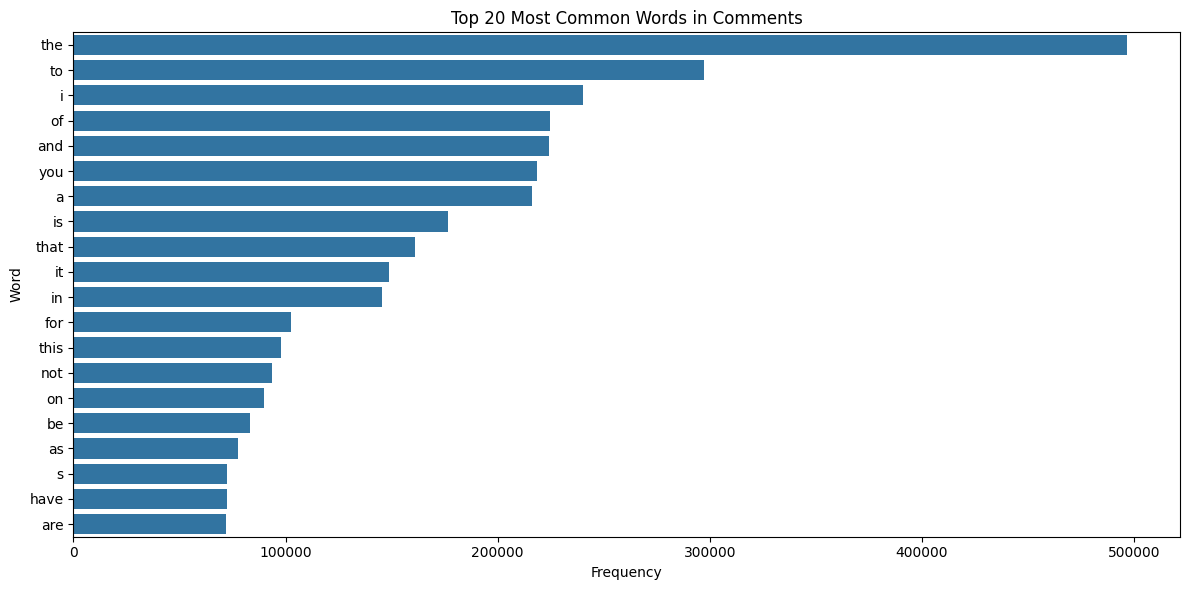

In [ ]:
#Visualize the Top 20 Most Common Words
# Convert common words into a DataFrame
common_words_df = pd.DataFrame(
    common_words,
    columns=['Word', 'Frequency']
)

# Plot the top 20 most common words
plt.figure(figsize=(12, 6))
sns.barplot(
    data=common_words_df,
    x='Frequency',
    y='Word'
)

plt.title("Top 20 Most Common Words in Comments")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

In [ ]:
#the Most Common Words After Removing Stopwords
import nltk
from nltk.corpus import stopwords
from collections import Counter
import re

# Download English stopwords
nltk.download('stopwords')

# Get English stopwords
stop_words = set(stopwords.words('english'))

# Extract words from all comments
all_text = " ".join(df['comment_text'].astype(str)).lower()
words = re.findall(r"\b[a-z]+\b", all_text)

# Remove stopwords
filtered_words = [
    word for word in words
    if word not in stop_words and len(word) > 1
]

# Find the 20 most common remaining words
common_words_filtered = Counter(filtered_words).most_common(20)

# Display results
for word, count in common_words_filtered:
    print(f"{word}: {count}")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


article: 57661
wikipedia: 48427
page: 46460
talk: 37094
please: 29794
would: 29323
one: 29179
like: 28008
see: 21603
also: 20641
think: 20084
know: 19144
people: 18468
edit: 18288
articles: 16712
use: 16594
time: 15885
may: 15611
user: 14101
thanks: 13904


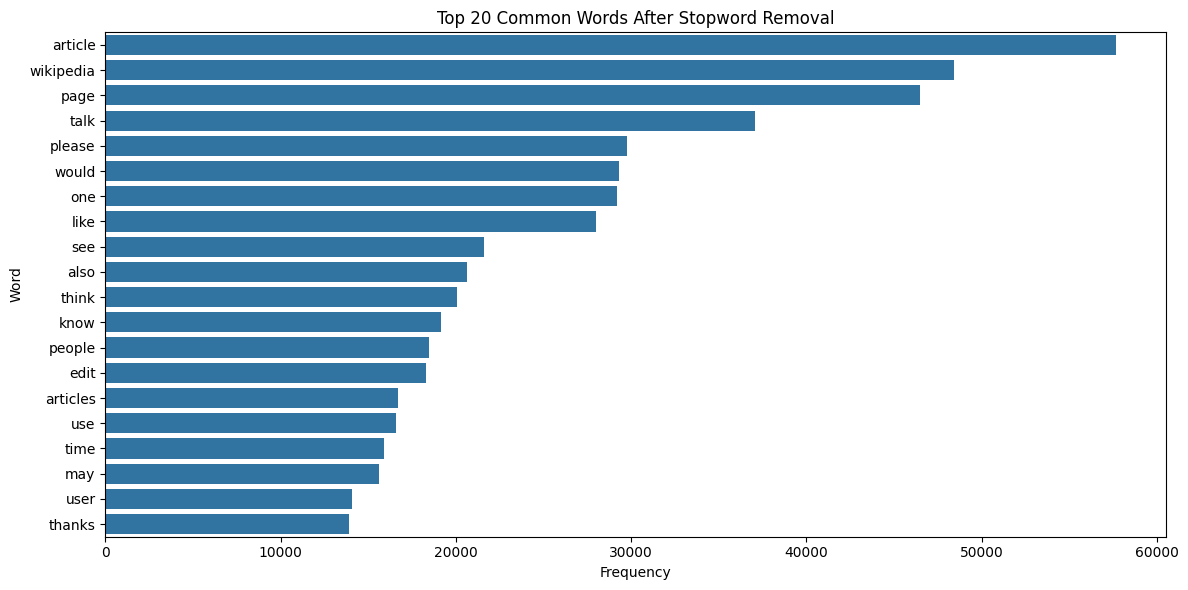

In [ ]:
#Visualize the Top 20 Words After Stopword Removal
# Convert filtered word frequencies into a DataFrame
common_words_filtered_df = pd.DataFrame(
    common_words_filtered,
    columns=['Word', 'Frequency']
)

# Plot the top 20 words
plt.figure(figsize=(12, 6))

sns.barplot(
    data=common_words_filtered_df,
    x='Frequency',
    y='Word'
)

plt.title("Top 20 Common Words After Stopword Removal")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

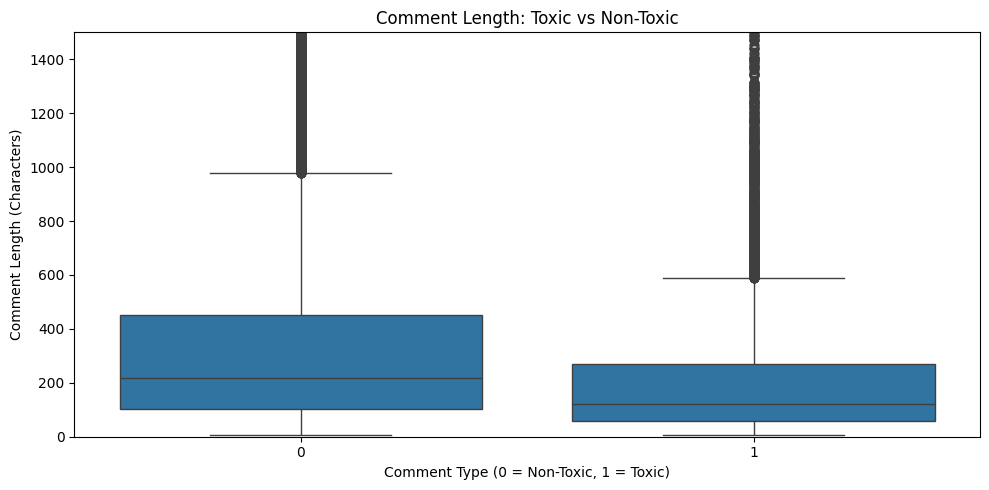

In [ ]:
# Compare comment lengths: Toxic vs Non-Toxic

plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df['toxic'],
    y=df['comment_length']
)

plt.title("Comment Length: Toxic vs Non-Toxic")
plt.xlabel("Comment Type (0 = Non-Toxic, 1 = Toxic)")
plt.ylabel("Comment Length (Characters)")
plt.ylim(0, 1500)

plt.tight_layout()
plt.show()

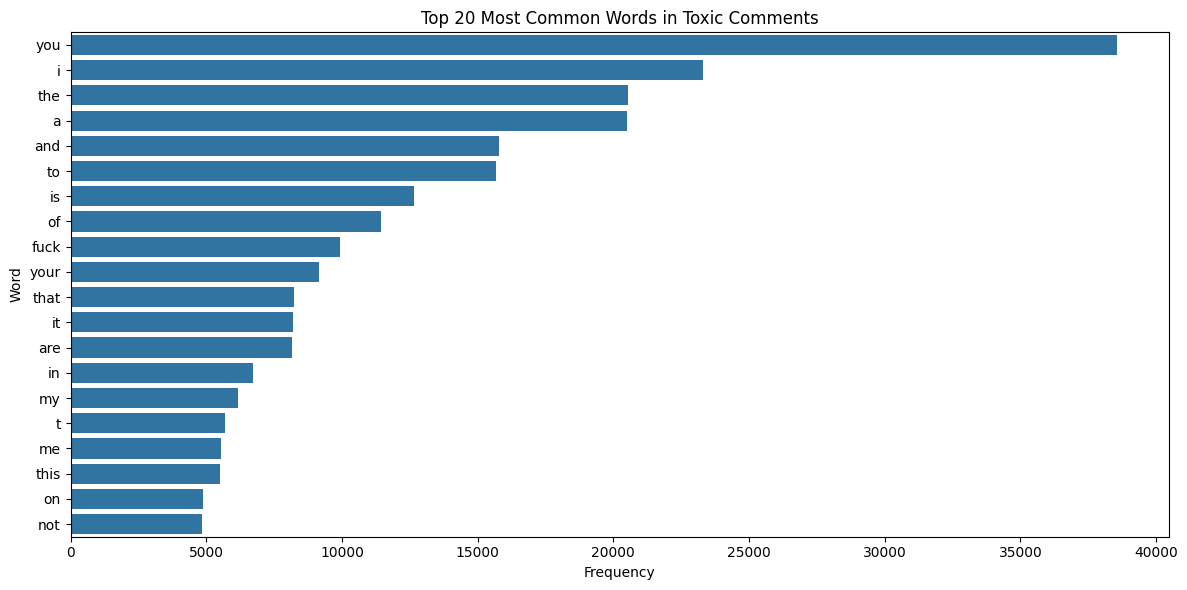

In [ ]:
#Top 20 Words in Toxic Comments
# Extract words from toxic comments only

toxic_text = " ".join(
    df.loc[df['toxic'] == 1, 'comment_text'].astype(str)
).lower()

toxic_words = re.findall(r'\b[a-z]+\b', toxic_text)

toxic_common_words = Counter(toxic_words).most_common(20)

# Display the top 20 words

toxic_words_df = pd.DataFrame(
    toxic_common_words,
    columns=['Word', 'Frequency']
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=toxic_words_df,
    x='Frequency',
    y='Word'
)

plt.title("Top 20 Most Common Words in Toxic Comments")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

**Text Preprocessing**

In [ ]:
# Step 1: Inspect Sample Comments Before Preprocessing

sample_comments = df[
    ['comment_text', 'toxic', 'severe_toxic',
     'obscene', 'threat', 'insult', 'identity_hate']
].sample(5, random_state=42)

sample_comments

,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
119105,"Geez, are you forgetful! We've already discus...",0,0,0,0,0,0
131631,Carioca RFA \n\nThanks for your support on my ...,0,0,0,0,0,0
125326,"""\n\n Birthday \n\nNo worries, It's what I do ...",0,0,0,0,0,0
111256,Pseudoscience category? \n\nI'm assuming that ...,0,0,0,0,0,0
83590,"(and if such phrase exists, it would be provid...",0,0,0,0,0,0


In [ ]:
# Step 2: Basic Text Cleaning

import re
import html

def basic_clean(text):
    text = html.unescape(str(text))
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    return text

df['cleaned_text'] = df['comment_text'].apply(basic_clean)

df[['comment_text', 'cleaned_text']].head()

,comment_text,cleaned_text
0,Explanation\nWhy the edits made under my usern...,Explanation Why the edits made under my userna...
1,D'aww! He matches this background colour I'm s...,D'aww! He matches this background colour I'm s...
2,"Hey man, I'm really not trying to edit war. It...","Hey man, I'm really not trying to edit war. It..."
3,"""\nMore\nI can't make any real suggestions on ...",""" More I can't make any real suggestions on im..."
4,"You, sir, are my hero. Any chance you remember...","You, sir, are my hero. Any chance you remember..."


In [ ]:
# Step 3: Text Normalization

df['normalized_text'] = df['cleaned_text'].str.lower()

df[['cleaned_text', 'normalized_text']].head()

,cleaned_text,normalized_text
0,Explanation Why the edits made under my userna...,explanation why the edits made under my userna...
1,D'aww! He matches this background colour I'm s...,d'aww! he matches this background colour i'm s...
2,"Hey man, I'm really not trying to edit war. It...","hey man, i'm really not trying to edit war. it..."
3,""" More I can't make any real suggestions on im...",""" more i can't make any real suggestions on im..."
4,"You, sir, are my hero. Any chance you remember...","you, sir, are my hero. any chance you remember..."


In [ ]:
# Step 4: Handling Special Characters and URLs

def handle_noise(text):
    text = re.sub(r'https?://\S+|www\.\S+', ' URL ', text)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['processed_text'] = df['normalized_text'].apply(handle_noise)

df[['normalized_text', 'processed_text']].head()

,normalized_text,processed_text
0,explanation why the edits made under my userna...,explanation why the edits made under my userna...
1,d'aww! he matches this background colour i'm s...,d'aww! he matches this background colour i'm s...
2,"hey man, i'm really not trying to edit war. it...","hey man, i'm really not trying to edit war. it..."
3,""" more i can't make any real suggestions on im...",""" more i can't make any real suggestions on im..."
4,"you, sir, are my hero. any chance you remember...","you, sir, are my hero. any chance you remember..."


In [ ]:
# Step 5: Tokenization

from tensorflow.keras.preprocessing.text import Tokenizer

toxicity_labels = [
    'toxic', 'severe_toxic', 'obscene',
    'threat', 'insult', 'identity_hate'
]

X_text = df['processed_text'].astype(str)
y = df[toxicity_labels].values

from sklearn.model_selection import train_test_split

X_train_text, X_val_text, y_train, y_val = train_test_split(
    X_text, y, test_size=0.2, random_state=42
)

MAX_WORDS = 30000

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token='<OOV>'
)

tokenizer.fit_on_texts(X_train_text)

print("Vocabulary size:", len(tokenizer.word_index))
print("Sample tokens:", list(tokenizer.word_index.items())[:20])

Vocabulary size: 175069
Sample tokens: [('<OOV>', 1), ('the', 2), ('to', 3), ('and', 4), ('of', 5), ('a', 6), ('you', 7), ('i', 8), ('is', 9), ('that', 10), ('in', 11), ('it', 12), ('for', 13), ('this', 14), ('not', 15), ('on', 16), ('be', 17), ('as', 18), ('have', 19), ('are', 20)]


In [ ]:
# Step 6: Converting Text into Numerical Sequences

X_train_sequences = tokenizer.texts_to_sequences(X_train_text)
X_val_sequences = tokenizer.texts_to_sequences(X_val_text)

print("Original comment:")
print(X_train_text.iloc[0])

print("\nNumerical sequence:")
print(X_train_sequences[0])

Original comment:
grandma terri should burn in trash grandma terri is trash. i hate grandma terri. f%%k her to hell! 71.74.76.40

Numerical sequence:
[12794, 8214, 57, 3973, 11, 4379, 12794, 8214, 9, 4379, 8, 394, 12794, 8214, 908, 1356, 184, 3, 858, 1692, 2591, 1718, 1327]


In [ ]:
# Step 7: Padding and Truncation

from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_LEN = 200

X_train_padded = pad_sequences(
    X_train_sequences,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

X_val_padded = pad_sequences(
    X_val_sequences,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

print("Training data shape:", X_train_padded.shape)
print("Validation data shape:", X_val_padded.shape)

print("\nSample padded sequence:")
print(X_train_padded[0])

Training data shape: (127656, 200)
Validation data shape: (31915, 200)

Sample padded sequence:
[12794  8214    57  3973    11  4379 12794  8214     9  4379     8   394
 12794  8214   908  1356   184     3   858  1692  2591  1718  1327     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0    

In [ ]:
# Step 8: Preparation of Input Features and Target Labels

X_train = X_train_padded
X_val = X_val_padded

print("Training input shape:", X_train.shape)
print("Training target shape:", y_train.shape)

print("\nValidation input shape:", X_val.shape)
print("Validation target shape:", y_val.shape)

print("\nTarget label order:")
print(toxicity_labels)

print("\nSample target labels:")
print(y_train[0])

Training input shape: (127656, 200)
Training target shape: (127656, 6)

Validation input shape: (31915, 200)
Validation target shape: (31915, 6)

Target label order:
['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

Sample target labels:
[1 0 0 0 0 0]


**Dataset Preparationxt**

In [ ]:
# Phase 4 - Step 1: Verify Train-Validation Split

print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))

print("\nTraining Percentage:",
      round(len(X_train) / len(df) * 100, 2), "%")

print("Validation Percentage:",
      round(len(X_val) / len(df) * 100, 2), "%")

print("\nTraining Data Shape:", X_train.shape)
print("Training Labels Shape:", y_train.shape)

print("\nValidation Data Shape:", X_val.shape)
print("Validation Labels Shape:", y_val.shape)

Training Samples: 127656
Validation Samples: 31915

Training Percentage: 80.0 %
Validation Percentage: 20.0 %

Training Data Shape: (127656, 200)
Training Labels Shape: (127656, 6)

Validation Data Shape: (31915, 200)
Validation Labels Shape: (31915, 6)


In [ ]:
# Phase 4 - Step 2: Preparation of Multi-Label Targets

print("Target Labels:", toxicity_labels)

print("\nTraining Target Shape:", y_train.shape)
print("Validation Target Shape:", y_val.shape)

print("\nSample Training Targets:")
print(y_train[:5])

print("\nNumber of Positive Labels per Sample:")
print(y_train[:5].sum(axis=1))

Target Labels: ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

Training Target Shape: (127656, 6)
Validation Target Shape: (31915, 6)

Sample Training Targets:
[[1 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]]

Number of Positive Labels per Sample:
[1 0 0 0 0]


Training Set Label Distribution:


,Toxicity Label,Positive Samples,Negative Samples,Positive Percentage
0,toxic,12238,115418,9.59
1,severe_toxic,1274,126382,1.00
2,obscene,6734,120922,5.28
3,threat,404,127252,0.32
4,insult,6263,121393,4.91
5,identity_hate,1111,126545,0.87


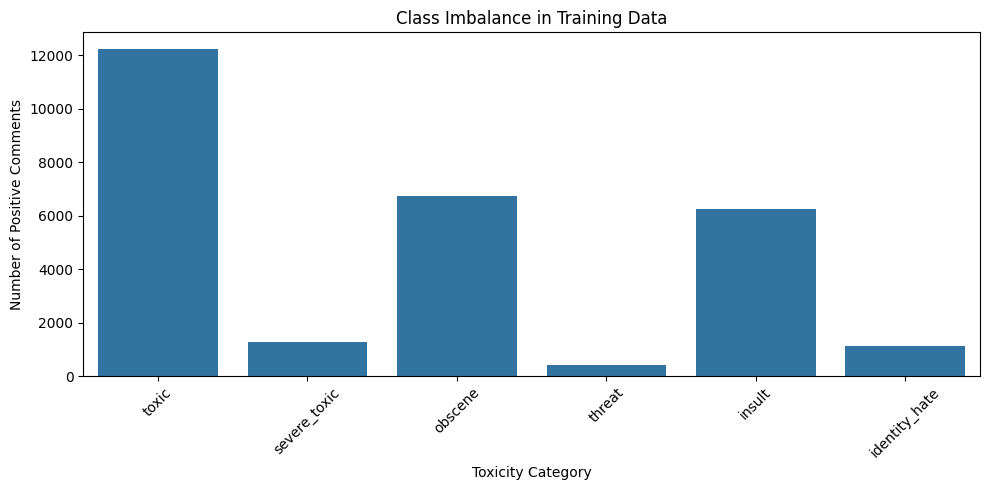

In [ ]:
# Phase 4 - Step 3: Analyze Class Imbalance

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

train_label_counts = pd.DataFrame({
    'Toxicity Label': toxicity_labels,
    'Positive Samples': y_train.sum(axis=0).astype(int),
    'Negative Samples': (len(y_train) - y_train.sum(axis=0)).astype(int)
})

train_label_counts['Positive Percentage'] = (
    train_label_counts['Positive Samples'] / len(y_train) * 100
).round(2)

print("Training Set Label Distribution:")
display(train_label_counts)

# Visualize positive samples for each label

plt.figure(figsize=(10, 5))
sns.barplot(
    data=train_label_counts,
    x='Toxicity Label',
    y='Positive Samples'
)

plt.title("Class Imbalance in Training Data")
plt.xlabel("Toxicity Category")
plt.ylabel("Number of Positive Comments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,Toxicity Label,Positive Samples,Negative Samples,Positive Percentage
0,toxic,12238,115418,9.59
1,severe_toxic,1274,126382,1.00
2,obscene,6734,120922,5.28
3,threat,404,127252,0.32
4,insult,6263,121393,4.91
5,identity_hate,1111,126545,0.87


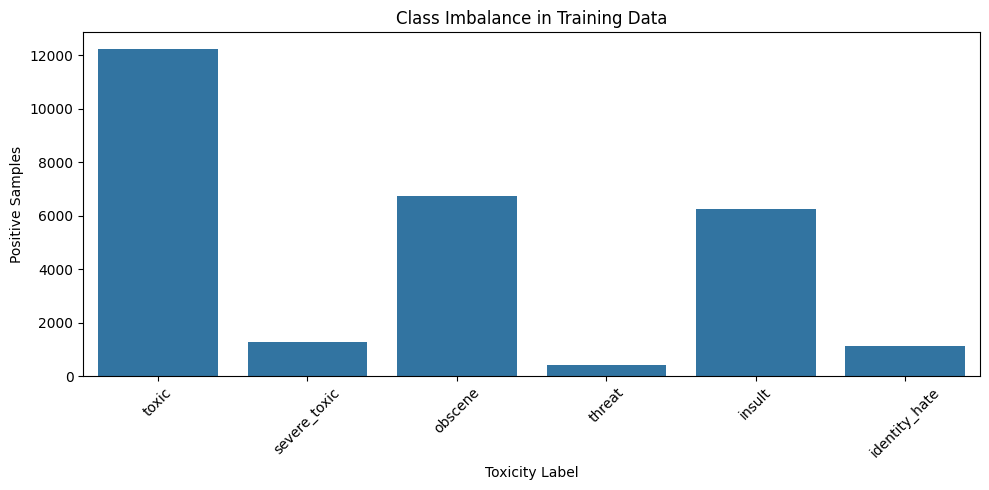

In [ ]:
# Phase 4 - Step 3: Analyze Class Imbalance

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

train_label_counts = pd.DataFrame({
    'Toxicity Label': toxicity_labels,
    'Positive Samples': y_train.sum(axis=0).astype(int),
    'Negative Samples': len(y_train) - y_train.sum(axis=0).astype(int)
})

train_label_counts['Positive Percentage'] = (
    train_label_counts['Positive Samples'] / len(y_train) * 100
).round(2)

display(train_label_counts)

plt.figure(figsize=(10, 5))
sns.barplot(data=train_label_counts, x='Toxicity Label',
            y='Positive Samples')
plt.title("Class Imbalance in Training Data")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Baseline Machine Learning Model**

In [ ]:
# Phase 5 - Step 1: TF-IDF Vectorization

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text)
X_val_tfidf = tfidf_vectorizer.transform(X_val_text)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Validation TF-IDF Shape:", X_val_tfidf.shape)
print("Vocabulary Size:", len(tfidf_vectorizer.vocabulary_))

Training TF-IDF Shape: (127656, 30000)
Validation TF-IDF Shape: (31915, 30000)
Vocabulary Size: 30000


In [ ]:
# Phase 5 - Step 2: Logistic Regression

from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression

baseline_model = OneVsRestClassifier(
    LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        solver='liblinear'
    )
)

baseline_model.fit(X_train_tfidf, y_train)

print("Baseline Logistic Regression training completed!")

Baseline Logistic Regression training completed!


In [ ]:
# Phase 5 - Step 3: Multi-Label Classification

baseline_predictions = baseline_model.predict(X_val_tfidf)

print("Prediction Shape:", baseline_predictions.shape)
print("\nFirst 5 Predictions:")
print(baseline_predictions[:5])

print("\nActual Labels:")
print(y_val[:5])

Prediction Shape: (31915, 6)

First 5 Predictions:
[[1 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]]

Actual Labels:
[[0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]]


In [ ]:
# Phase 5 - Step 4: Baseline Predictions

baseline_probabilities = baseline_model.predict_proba(X_val_tfidf)

sample_index = 0

baseline_result = pd.DataFrame({
    'Toxicity Label': toxicity_labels,
    'Actual': y_val[sample_index],
    'Predicted': baseline_predictions[sample_index],
    'Probability': baseline_probabilities[sample_index].round(4)
})

display(baseline_result)

,Toxicity Label,Actual,Predicted,Probability
0,toxic,0,1,0.6459
1,severe_toxic,0,0,0.0322
2,obscene,0,0,0.1232
3,threat,0,0,0.0251
4,insult,0,0,0.2406
5,identity_hate,0,0,0.2254


**Deep Learning Model — Bidirectional LSTM**

In [ ]:
import numpy as np
import tensorflow as tf

tf.random.set_seed(42)
np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Define Vocabulary Size

vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)

print("Input shape:", X_train.shape)
print("Vocabulary size:", vocab_size)
print("Maximum sequence length:", MAX_LEN)
print("Number of output labels:", len(toxicity_labels))

Input shape: (127656, 200)
Vocabulary size: 30000
Maximum sequence length: 200
Number of output labels: 6


In [ ]:
# Phase 6 - Step 1: Model Architecture Design

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Embedding, Bidirectional, LSTM,
    Dense, Dropout, SpatialDropout1D
)

tf.random.set_seed(42)
np.random.seed(42)

print("Input shape:", X_train.shape)
print("Vocabulary size:", vocab_size)
print("Maximum sequence length:", MAX_LEN)
print("Number of output labels:", len(toxicity_labels))

Input shape: (127656, 200)
Vocabulary size: 30000
Maximum sequence length: 200
Number of output labels: 6


In [ ]:
# Phase 6 - Steps 2 to 5: Build the BiLSTM Architecture

model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        mask_zero=True
    ),
    SpatialDropout1D(0.2),
    Bidirectional(LSTM(64)),
    Dropout(0.4),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(6, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 200, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,947,462 (15.06 MB)

 Trainable params: 3,947,462 (15.06 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Phase 6 - Step 6: Compile the Model

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.AUC(
            multi_label=True,
            num_labels=6,
            name='auc'
        )
    ]
)

print("Model compiled successfully!")

Model compiled successfully!


In [47]:
# Phase 6 - Step 7: Train the BiLSTM

  from tensorflow.keras.callbacks import EarlyStopping

  early_stopping = EarlyStopping(
      monitor='val_loss',
      patience=2,
      restore_best_weights=True
  )

  history = model.fit(
      X_train,
      y_train,
      validation_data=(X_val, y_val),
      epochs=8,
      batch_size=128,
      callbacks=[early_stopping],
      verbose=1
  )

Epoch 1/8
998/998 ━━━━━━━━━━━━━━━━━━━━ 972s 973ms/step - auc: 0.9798 - loss: 0.0370 - val_auc: 0.9606 - val_loss: 0.0520
Epoch 2/8
998/998 ━━━━━━━━━━━━━━━━━━━━ 986s 989ms/step - auc: 0.9849 - loss: 0.0328 - val_auc: 0.9509 - val_loss: 0.0585
Epoch 3/8
998/998 ━━━━━━━━━━━━━━━━━━━━ 958s 959ms/step - auc: 0.9877 - loss: 0.0293 - val_auc: 0.9433 - val_loss: 0.0657


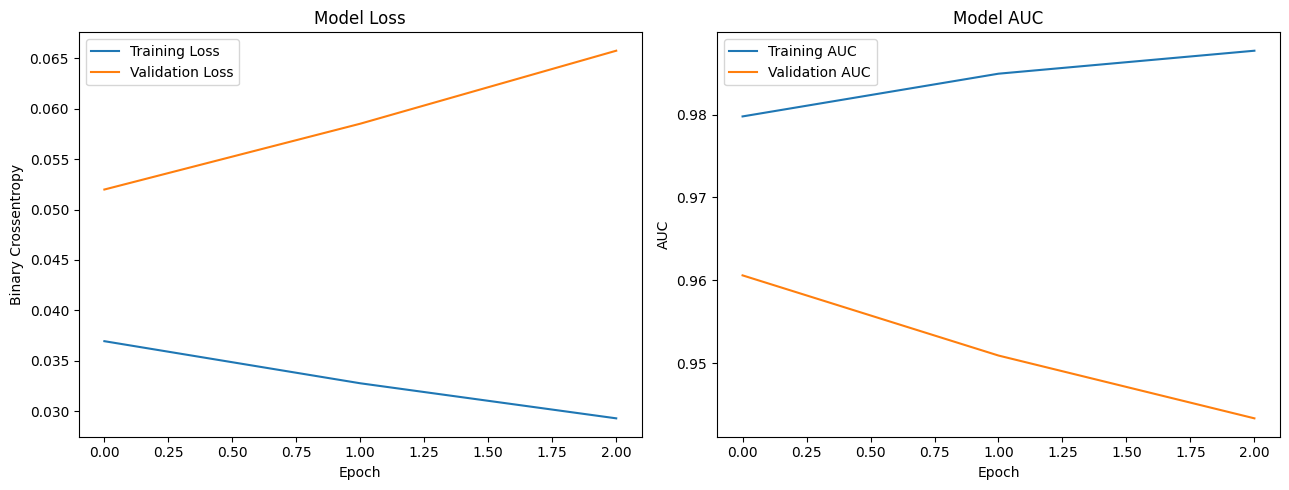

In [48]:
# Phase 6 - Step 8: Plot Training History

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(history.history['loss'], label='Training Loss')
axes[0].plot(history.history['val_loss'], label='Validation Loss')
axes[0].set_title('Model Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary Crossentropy')
axes[0].legend()

axes[1].plot(history.history['auc'], label='Training AUC')
axes[1].plot(history.history['val_auc'], label='Validation AUC')
axes[1].set_title('Model AUC')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('AUC')
axes[1].legend()

plt.tight_layout()
plt.show()

**Model Evaluation**

In [49]:
# Phase 7 - Step 1: Evaluation Metrics

from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    accuracy_score, classification_report
)

bi_probabilities = model.predict(X_val, batch_size=256)

# Initial threshold; we can tune it later using validation data
bi_predictions = (bi_probabilities >= 0.5).astype(int)

print("Micro F1:", round(f1_score(y_val, bi_predictions, average='micro', zero_division=0), 4))
print("Macro F1:", round(f1_score(y_val, bi_predictions, average='macro', zero_division=0), 4))
print("Micro Precision:", round(precision_score(y_val, bi_predictions, average='micro', zero_division=0), 4))
print("Micro Recall:", round(recall_score(y_val, bi_predictions, average='micro', zero_division=0), 4))
print("Exact-match accuracy:", round(accuracy_score(y_val, bi_predictions), 4))

125/125 ━━━━━━━━━━━━━━━━━━━━ 69s 546ms/step
Micro F1: 0.7372
Macro F1: 0.4428
Micro Precision: 0.7895
Micro Recall: 0.6914
Exact-match accuracy: 0.9165


In [50]:
# Phase 7 - Step 2: Classification Report

print(classification_report(
    y_val,
    bi_predictions,
    target_names=toxicity_labels,
    zero_division=0
))

               precision    recall  f1-score   support

        toxic       0.80      0.78      0.79      3056
 severe_toxic       0.58      0.22      0.32       321
      obscene       0.86      0.77      0.81      1715
       threat       0.00      0.00      0.00        74
       insult       0.72      0.70      0.71      1614
identity_hate       0.50      0.02      0.03       294

    micro avg       0.79      0.69      0.74      7074
    macro avg       0.58      0.41      0.44      7074
 weighted avg       0.77      0.69      0.71      7074
  samples avg       0.07      0.06      0.06      7074



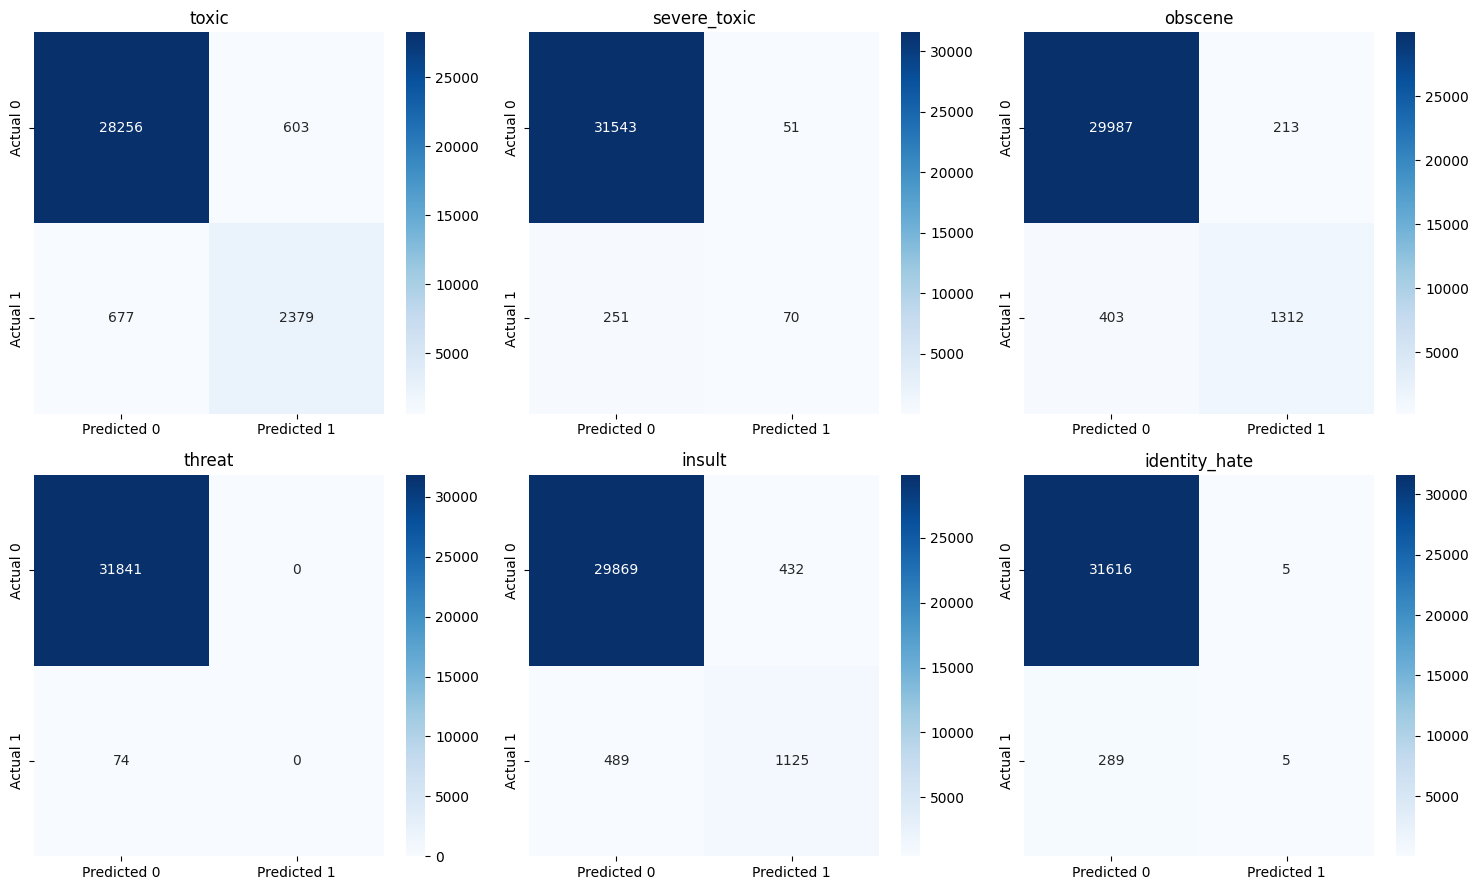

In [51]:
# Phase 7 - Step 3: Confusion Matrices for Each Label

from sklearn.metrics import multilabel_confusion_matrix

cms = multilabel_confusion_matrix(y_val, bi_predictions)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i, ax in enumerate(axes.flat):
    sns.heatmap(
        cms[i],
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Predicted 0', 'Predicted 1'],
        yticklabels=['Actual 0', 'Actual 1'],
        ax=ax
    )
    ax.set_title(toxicity_labels[i])

plt.tight_layout()
plt.show()

In [52]:
# Phase 7 - Step 5: Inspect Incorrect Predictions

incorrect_indices = np.where(
    np.any(y_val != bi_predictions, axis=1)
)[0]

print("Comments with at least one incorrect label:", len(incorrect_indices))

for idx in incorrect_indices[:5]:
    print("\nComment:", X_val_text.iloc[idx][:300])
    print("Actual:   ", y_val[idx])
    print("Predicted:", bi_predictions[idx])
    print("Probabilities:", np.round(bi_probabilities[idx], 3))

Comments with at least one incorrect label: 2666

Comment: no worries we will use another account, and will not stop until wikipedia stops pushing the evil, sin filled gay agenda
Actual:    [1 0 0 0 0 1]
Predicted: [1 0 0 0 0 0]
Probabilities: [0.767 0.004 0.084 0.017 0.254 0.094]

Comment: suck my dikkkkk == suck my dikkkkk gogo gogo giving blowjobs on demand
Actual:    [1 1 1 0 1 0]
Predicted: [1 0 1 0 1 0]
Probabilities: [1.    0.337 0.997 0.007 0.853 0.045]

Comment: hi kannadiga shame on you you look like a terrible ass now with that false citation, kannadiga. where did you say urdu originate? africa? despite all the lies and idiocy you spewed, you and a handful of kanndadigas think you are a valuable encyclopedic contributor!
Actual:    [1 0 0 0 1 0]
Predicted: [1 0 1 0 1 0]
Probabilities: [0.971 0.141 0.846 0.037 0.724 0.148]

Comment: " sockpuppet? oh no stifle. just what do you think your doing? i've worked too hard for you to do this. and why? dont assume, look at my contribu

**Prediction and Testing**

In [57]:
# Phase 8 - Step 1: Define New Comments

new_comments = [
    "You are a wonderful person and very helpful.",
    "You are stupid and nobody likes you.",
    "I disagree with your opinion.",
    "You are an idiot and a disgusting person.",
    "Thank you for helping me with this project.",
    "I will hurt you if you come here."
]

print("Number of test comments:", len(new_comments))

for i, comment in enumerate(new_comments, start=1):
    print(f"{i}. {comment}")

Number of test comments: 6
1. You are a wonderful person and very helpful.
2. You are stupid and nobody likes you.
3. I disagree with your opinion.
4. You are an idiot and a disgusting person.
5. Thank you for helping me with this project.
6. I will hurt you if you come here.


In [58]:
# Phase 8 - Step 2: Preprocess New Comments

cleaned_comments = [
    handle_noise(basic_clean(comment).lower())
    for comment in new_comments
]

for original, cleaned in zip(new_comments, cleaned_comments):
    print("Original:", original)
    print("Cleaned :", cleaned)
    print("-" * 60)

Original: You are a wonderful person and very helpful.
Cleaned : you are a wonderful person and very helpful.
------------------------------------------------------------
Original: You are stupid and nobody likes you.
Cleaned : you are stupid and nobody likes you.
------------------------------------------------------------
Original: I disagree with your opinion.
Cleaned : i disagree with your opinion.
------------------------------------------------------------
Original: You are an idiot and a disgusting person.
Cleaned : you are an idiot and a disgusting person.
------------------------------------------------------------
Original: Thank you for helping me with this project.
Cleaned : thank you for helping me with this project.
------------------------------------------------------------
Original: I will hurt you if you come here.
Cleaned : i will hurt you if you come here.
------------------------------------------------------------


In [59]:
# Phase 8 - Step 3: Tokenize New Comments

new_sequences = tokenizer.texts_to_sequences(cleaned_comments)

print("First comment sequence:")
print(new_sequences[0])

print("\nNumber of test sequences:", len(new_sequences))

First comment sequence:
[7, 20, 6, 3630, 214, 4, 102, 813]

Number of test sequences: 6


In [60]:
# Phase 8 - Step 4: Pad Sequences

from tensorflow.keras.preprocessing.sequence import pad_sequences

new_padded = pad_sequences(
    new_sequences,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

print("Padded input shape:", new_padded.shape)

Padded input shape: (6, 200)


In [61]:
# Phase 8 - Step 5: Predict Toxicity

new_probabilities = model.predict(new_padded, verbose=0)

new_predictions = (new_probabilities >= 0.5).astype(int)

print("Probability shape:", new_probabilities.shape)
print("Prediction shape:", new_predictions.shape)

Probability shape: (6, 6)
Prediction shape: (6, 6)


In [62]:
# Phase 8 - Step 6: Create Prediction Table

import pandas as pd

prediction_table = pd.DataFrame(
    new_predictions,
    columns=toxicity_labels
)

prediction_table.insert(0, 'Comment', new_comments)

display(prediction_table)

,Comment,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,You are a wonderful person and very helpful.,0,0,0,0,0,0
1,You are stupid and nobody likes you.,1,0,0,0,1,0
2,I disagree with your opinion.,0,0,0,0,0,0
3,You are an idiot and a disgusting person.,1,0,0,0,1,0
4,Thank you for helping me with this project.,0,0,0,0,0,0
5,I will hurt you if you come here.,0,0,0,0,0,0


In [63]:
# Phase 8 - Step 7: View Prediction Probabilities

probability_table = pd.DataFrame(
    new_probabilities,
    columns=toxicity_labels
)

probability_table.insert(0, 'Comment', new_comments)

display(probability_table.round(3))

,Comment,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,You are a wonderful person and very helpful.,0.023,0.000,0.003,0.001,0.001,0.001
1,You are stupid and nobody likes you.,0.984,0.017,0.391,0.004,0.698,0.052
2,I disagree with your opinion.,0.006,0.000,0.001,0.000,0.000,0.000
3,You are an idiot and a disgusting person.,0.994,0.015,0.436,0.002,0.782,0.047
4,Thank you for helping me with this project.,0.000,0.000,0.000,0.000,0.000,0.000
5,I will hurt you if you come here.,0.214,0.001,0.022,0.010,0.025,0.014


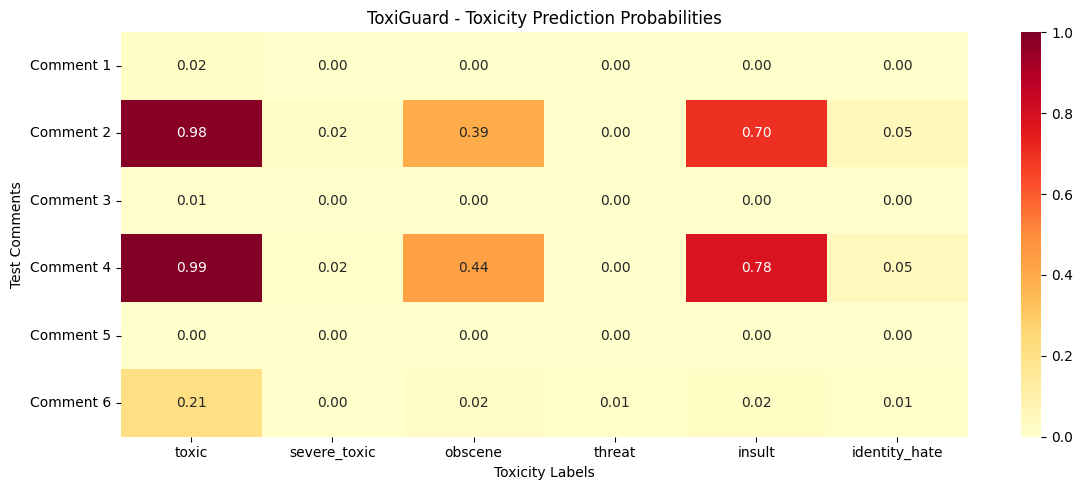

In [64]:
# Phase 8 - Step 8: Prediction Probability Heatmap

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

sns.heatmap(
    new_probabilities,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    xticklabels=toxicity_labels,
    yticklabels=[f'Comment {i}' for i in range(1, len(new_comments) + 1)],
    vmin=0,
    vmax=1
)

plt.title('ToxiGuard - Toxicity Prediction Probabilities')
plt.xlabel('Toxicity Labels')
plt.ylabel('Test Comments')
plt.tight_layout()
plt.show()

**Model Saving and Export**

In [65]:
# Phase 9 - Step 1: Save the Trained Model

model.save('/content/toxiguard_bilstm.keras')

print("BiLSTM model saved successfully!")

BiLSTM model saved successfully!


In [66]:
# Phase 9 - Step 2: Save the Tokenizer

import pickle

with open('/content/toxiguard_tokenizer.pkl', 'wb') as file:
    pickle.dump(tokenizer, file)

print("Tokenizer saved successfully!")

Tokenizer saved successfully!


In [67]:
# Phase 9 - Step 3: Save Model Configuration

import json

config = {
    'project_name': 'ToxiGuard',
    'model_type': 'Bidirectional LSTM',
    'max_words': MAX_WORDS,
    'max_sequence_length': MAX_LEN,
    'vocabulary_size': vocab_size,
    'toxicity_labels': toxicity_labels,
    'prediction_threshold': 0.5
}

with open('/content/toxiguard_config.json', 'w') as file:
    json.dump(config, file, indent=4)

print("Model configuration saved successfully!")

Model configuration saved successfully!


In [68]:
# Phase 9 - Step 4: Verify Saved Files

import os

saved_files = [
    '/content/toxiguard_bilstm.keras',
    '/content/toxiguard_tokenizer.pkl',
    '/content/toxiguard_config.json'
]

for file_path in saved_files:
    if os.path.exists(file_path):
        size_mb = os.path.getsize(file_path) / (1024 * 1024)
        print(f"Saved: {os.path.basename(file_path)} | {size_mb:.2f} MB")
    else:
        print(f"Missing: {os.path.basename(file_path)}")

Saved: toxiguard_bilstm.keras | 45.22 MB
Saved: toxiguard_tokenizer.pkl | 7.50 MB
Saved: toxiguard_config.json | 0.00 MB


In [69]:
# Phase 9 - Step 5: Download the Model

from google.colab import files

files.download('/content/toxiguard_bilstm.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [70]:
files.download('/content/toxiguard_tokenizer.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [71]:
files.download('/content/toxiguard_config.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **Conclusion**

This project applied Natural Language Processing (NLP) and deep learning techniques to detect potentially toxic comments and classify them into six toxicity categories.

**EDA and Text Preprocessing**

Exploratory Data Analysis was performed to understand toxicity label distributions, comment lengths, frequent words, and class imbalance. Text cleaning, normalization, tokenization, and sequence padding were applied to prepare the comments for model training.

**Baseline Machine Learning Model**

TF-IDF vectorization and Logistic Regression were used to build a baseline multi-label classification model for comparison with the deep learning approach.

**Bidirectional LSTM Model**

A Bidirectional LSTM model was developed to classify comments into toxic, severe toxic, obscene, threat, insult, and identity hate categories. Dropout regularization and early stopping were used to help reduce overfitting during training.

**Model Evaluation and Prediction**

The model was evaluated using classification metrics such as precision, recall, F1-score, and ROC-AUC. Predictions were also generated for new comments to examine the model's ability to identify different toxicity categories.

**Key Insights**

- Toxic comment detection is a multi-label classification problem because a comment can belong to multiple toxicity categories.
- Class imbalance is an important challenge, particularly for rare labels such as threat and identity hate.
- Text preprocessing and sequence preparation play an important role in NLP model development.
- Combining a traditional machine learning baseline with a deep learning model enables performance comparison.
- Automated toxicity detection can support content moderation, although predictions may include false positives and false negatives.

**Overall Outcome**

The project demonstrates the application of NLP, Logistic Regression, and Bidirectional LSTM for automated toxic comment classification. It strengthened practical understanding of text preprocessing, multi-label classification, deep learning model development, and model evaluation.